## Install Dependencies

In [1]:
!pip install -q transformers evaluate rouge_score sacrebleu huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 10.3 MB/s eta 0:00:00


## Importing Libraries

In [2]:
import os
import json
import evaluate
import torch
import torch.nn as nn
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, get_cosine_schedule_with_warmup
from transformers.modeling_outputs import BaseModelOutput
from transformers import ViTImageProcessor, VisionEncoderDecoderModel, ViTModel, GPT2LMHeadModel, GPT2Config
from huggingface_hub import HfApi, login
from kaggle_secrets import UserSecretsClient

## Environment Setup

In [3]:
ROOT_DIR = '/kaggle/input/datasets/utkarshshukla040/levir-cc-cv/Levir-CC-dataset'
JSON_PATH = os.path.join(ROOT_DIR, 'LevirCCcaptions.json')
IMAGES_DIR = os.path.join(ROOT_DIR, 'images')

tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

## Data Loader

In [4]:
class LevirCC_Siamese_Dataset(Dataset):
    def __init__(self, json_path, images_dir, split='train'):
        with open(json_path, 'r') as f:
            data = json.load(f)
            
        self.images_dir = images_dir
        self.samples = [item for item in data['images'] if item['split'] == split]
        
        self.processor = ViTImageProcessor.from_pretrained("nlpconnect/vit-gpt2-image-captioning")
        self.tokenizer = AutoTokenizer.from_pretrained("nlpconnect/vit-gpt2-image-captioning")
        
        # GPT2 doesn't have a pad token by default
        if self.tokenizer.pad_token is None:
            self.tokenizer.pad_token = self.tokenizer.eos_token
            
    def __len__(self):
        return len(self.samples)
        
    def __getitem__(self, idx):
        item = self.samples[idx]
        filename = item['filename']
        split_dir = item['filepath'] 
        
        path_a = os.path.join(self.images_dir, split_dir, 'A', filename)
        path_b = os.path.join(self.images_dir, split_dir, 'B', filename)
        
        img_a = Image.open(path_a).convert('RGB')
        img_b = Image.open(path_b).convert('RGB')
        
        pixel_values_a = self.processor(img_a, return_tensors="pt").pixel_values.squeeze()
        pixel_values_b = self.processor(img_b, return_tensors="pt").pixel_values.squeeze()
        
        caption = item['sentences'][0]['raw'].strip()
        
        # Tokenize text
        labels = self.tokenizer(
            caption, 
            return_tensors="pt", 
            padding="max_length", 
            max_length=40, 
            truncation=True
        ).input_ids.squeeze()
        
        # Ignore pad tokens in loss calculation
        labels[labels == self.tokenizer.pad_token_id] = -100
        
        return {
            'pixel_values_a': pixel_values_a,
            'pixel_values_b': pixel_values_b,
            'labels': labels,
            'caption': caption
        }

train_dataset = LevirCC_Siamese_Dataset(JSON_PATH, IMAGES_DIR, split='train')
test_dataset = LevirCC_Siamese_Dataset(JSON_PATH, IMAGES_DIR, split='test')

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=2)

preprocessor_config.json:   0%|          | 0.00/228 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/241 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/120 [00:00<?, ?B/s]

## Verify Data

--- Data Validation ---


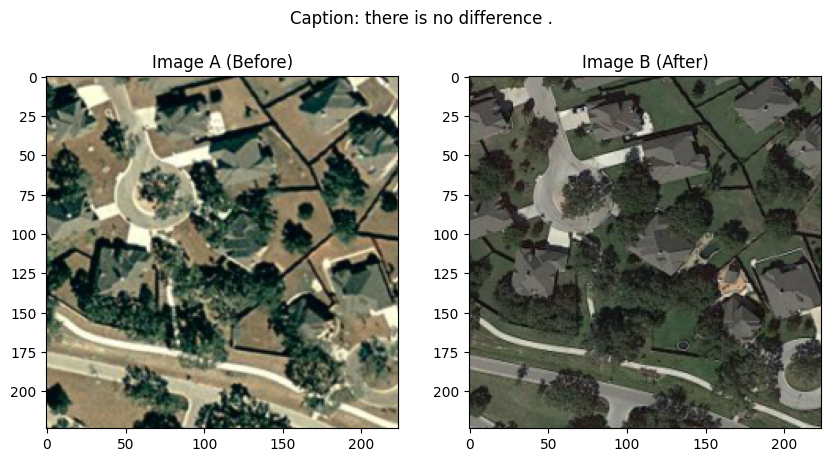

In [5]:
def validate_data(dataset):
    print("--- Data Validation ---")
    data = dataset[0] # Grab the first sample
    
    # Denormalize based on ViTImageProcessor's 0.5 mean and std
    inv_transform = T.Compose([
        T.Normalize(mean=[0, 0, 0], std=[1/0.5, 1/0.5, 1/0.5]),
        T.Normalize(mean=[-0.5, -0.5, -0.5], std=[1, 1, 1])
    ])
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    
    # Target the new pixel_values keys
    axes[0].imshow(inv_transform(data['pixel_values_a']).permute(1, 2, 0).clip(0, 1))
    axes[0].set_title("Image A (Before)")
    
    axes[1].imshow(inv_transform(data['pixel_values_b']).permute(1, 2, 0).clip(0, 1))
    axes[1].set_title("Image B (After)")
    
    plt.suptitle(f"Caption: {data['caption']}")
    plt.show()

validate_data(train_dataset)

## Model Definition

In [6]:
class SiameseBiTemporalCaptioner(nn.Module):
    def __init__(self, model_name="nlpconnect/vit-gpt2-image-captioning"):
        super().__init__()
        # Load the base model with pre-trained weights intact
        self.model = VisionEncoderDecoderModel.from_pretrained(model_name)
        
        for param in self.model.encoder.parameters():
            param.requires_grad = False

    def forward(self, pixel_values_a, pixel_values_b, labels=None):
        outputs_a = self.model.encoder(pixel_values=pixel_values_a, return_dict=True)
        outputs_b = self.model.encoder(pixel_values=pixel_values_b, return_dict=True)
        
        # Concatenate along the sequence dimension
        combined_hidden_states = torch.cat([
            outputs_a.last_hidden_state, 
            outputs_b.last_hidden_state
        ], dim=1)
        
        # Pass the fused features directly to the decoder
        outputs = self.model(
            encoder_outputs=(combined_hidden_states,), 
            labels=labels
        )
        return outputs
        
    def generate(self, pixel_values_a, pixel_values_b, **kwargs):
        outputs_a = self.model.encoder(pixel_values=pixel_values_a, return_dict=True)
        outputs_b = self.model.encoder(pixel_values=pixel_values_b, return_dict=True)
        
        combined_hidden_states = torch.cat([
            outputs_a.last_hidden_state, 
            outputs_b.last_hidden_state
        ], dim=1)
        
        return self.model.generate(
            encoder_outputs=(combined_hidden_states,), 
            **kwargs
        )

## Training

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SiameseBiTemporalCaptioner().to(device)

# We only pass gradients for the decoder since the encoder is frozen
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()), 
    lr=5e-5, 
    weight_decay=0.01
)

epochs = 10
total_steps = len(train_loader) * epochs
scheduler = get_cosine_schedule_with_warmup(
    optimizer, 
    num_warmup_steps=int(0.1 * total_steps), 
    num_training_steps=total_steps
)

os.makedirs("/kaggle/working/weights", exist_ok=True)
weights_path = "/kaggle/working/weights/levir_siamese_captioner.pth"
best_loss = float('inf')

print(f"Starting Siamese Training on {device}...")

for epoch in range(epochs):
    model.train()
    total_loss = 0
    
    for step, batch in enumerate(train_loader):
        pixel_values_a = batch['pixel_values_a'].to(device)
        pixel_values_b = batch['pixel_values_b'].to(device)
        labels = batch['labels'].to(device)
        
        optimizer.zero_grad()
        
        outputs = model(
            pixel_values_a=pixel_values_a, 
            pixel_values_b=pixel_values_b, 
            labels=labels
        )
        
        loss = outputs.loss
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        scheduler.step()
        
        total_loss += loss.item()
            
    avg_loss = total_loss / len(train_loader)
    print(f"--- Epoch {epoch+1} Avg Loss: {avg_loss:.4f} ---")
    
    if avg_loss < best_loss:
        best_loss = avg_loss
        torch.save(model.state_dict(), weights_path)
        print("Improved weights saved to disk.")

pytorch_model.bin:   0%|          | 0.00/982M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/445 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie decoder.transformer.wte.weight to decoder.lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
VisionEncoderDecoderModel LOAD REPORT from: nlpconnect/vit-gpt2-image-captioning
Key                                                       | Status     |  | 
----------------------------------------------------------+------------+--+-
decoder.transformer.h.{0...11}.attn.bias                  | UNEXPECTED |  | 
decoder.transformer.h.{0...11}.crossattention.masked_bias | UNEXPECTED |  | 
decoder.transformer.h.{0...11}.attn.masked_bias           | UNEXPECTED |  | 
decoder.transformer.h.{0...11}.crossattention.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/982M [00:00<?, ?B/s]

Starting Siamese Training on cuda...


We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.
You may ignore this warning if your `pad_token_id` (50256) is identical to the `bos_token_id` (50256), `eos_token_id` (50256), or the `sep_token_id` (None), and your input is not padded.


--- Epoch 1 Avg Loss: 1.7971 ---
Improved weights saved to disk.
--- Epoch 2 Avg Loss: 1.0497 ---
Improved weights saved to disk.
--- Epoch 3 Avg Loss: 0.9186 ---
Improved weights saved to disk.
--- Epoch 4 Avg Loss: 0.8232 ---
Improved weights saved to disk.
--- Epoch 5 Avg Loss: 0.7414 ---
Improved weights saved to disk.
--- Epoch 6 Avg Loss: 0.6530 ---
Improved weights saved to disk.
--- Epoch 7 Avg Loss: 0.5802 ---
Improved weights saved to disk.
--- Epoch 8 Avg Loss: 0.5166 ---
Improved weights saved to disk.
--- Epoch 9 Avg Loss: 0.4799 ---
Improved weights saved to disk.
--- Epoch 10 Avg Loss: 0.4618 ---
Improved weights saved to disk.


## Evaluation

In [9]:
print("\n--- Initializing Evaluation Metrics ---")
rouge_metric = evaluate.load("rouge")
bleu_metric = evaluate.load("sacrebleu")

weights_path = "/kaggle/working/weights/levir_siamese_captioner.pth"
if not os.path.exists(weights_path):
    raise FileNotFoundError(f"Weights file not found at: {weights_path}")
    
model.load_state_dict(torch.load(weights_path, map_location=device))
model.to(device)
model.eval()

eval_tokenizer = test_dataset.tokenizer
predictions = []
references_bleu = []
references_rouge = []

print("Calculating Test Metrics using Beam Search...")
with torch.no_grad():
    for step, batch in enumerate(test_loader):
        # 1. Correct keys for LevirCC_Siamese_Dataset
        pixel_values_a = batch['pixel_values_a'].to(device)
        pixel_values_b = batch['pixel_values_b'].to(device)
        caps = batch['caption']
        
        # 2. Extract features manually using the underlying Hugging Face encoder
        # return_dict=True guarantees the output has the .last_hidden_state attribute
        outputs_a = model.model.encoder(pixel_values=pixel_values_a, return_dict=True)
        outputs_b = model.model.encoder(pixel_values=pixel_values_b, return_dict=True)
        
        # 3. Concatenate the temporal features
        combined_hidden_states = torch.cat([
            outputs_a.last_hidden_state, 
            outputs_b.last_hidden_state
        ], dim=1)
        
        # 4. Wrap in BaseModelOutput
        encoder_outputs = BaseModelOutput(last_hidden_state=combined_hidden_states)
        
        # 5. Generate using the underlying Hugging Face model directly
        generated_ids = model.model.generate(
            encoder_outputs=encoder_outputs,
            max_new_tokens=40,
            num_beams=4,
            length_penalty=1.2,
            no_repeat_ngram_size=3,
            early_stopping=True
        )
        
        preds = eval_tokenizer.batch_decode(generated_ids, skip_special_tokens=True)
        
        predictions.extend(preds)
        references_bleu.extend([[c] for c in caps])  # Nested list for SacreBLEU
        references_rouge.extend(caps)                # Flat list for ROUGE

rouge_score = rouge_metric.compute(predictions=predictions, references=references_rouge)
bleu_score = bleu_metric.compute(predictions=predictions, references=references_bleu)

print("\n" + "=" * 45)
print("             OPTIMIZED TEST SET SCORES       ")
print("=" * 45)
print(f"SacreBLEU Score: {bleu_score['score']:.2f}")
print(f"ROUGE-1 Score:   {rouge_score['rouge1']:.4f}")
print(f"ROUGE-2 Score:   {rouge_score['rouge2']:.4f}")
print(f"ROUGE-L Score:   {rouge_score['rougeL']:.4f}")
print("=" * 45)


--- Initializing Evaluation Metrics ---
Calculating Test Metrics using Beam Search...


The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.



             OPTIMIZED TEST SET SCORES       
SacreBLEU Score: 6.72
ROUGE-1 Score:   0.2432
ROUGE-2 Score:   0.1410
ROUGE-L Score:   0.2155


## Hugging Face upload

In [10]:
import os
from getpass import getpass
from huggingface_hub import HfApi, login
from kaggle_secrets import UserSecretsClient

weights_path = "/kaggle/working/weights/levir_siamese_captioner.pth"

# Strict File Verification
if not os.path.exists(weights_path):
    raise FileNotFoundError(f"Weights file missing at {weights_path}. Training must complete at least 1 epoch.")

# Authentication with fallback
try:
    user_secrets = UserSecretsClient()
    hf_token = user_secrets.get_secret("HF_TOKEN")
    print("Authenticating via Kaggle Secrets...")
except Exception:
    print("HF_TOKEN secret not found. Please provide it manually:")
    hf_token = getpass("Hugging Face Write Token: ")

login(token=hf_token.strip())

# Cloud Export
repo_id = "nillohitroy/levir-cc-bitemporal-captioner"
api = HfApi()

print(f"Creating repository: {repo_id}...")
api.create_repo(repo_id=repo_id, repo_type="model", exist_ok=True)

print("Uploading weights to the Hub...")
api.upload_file(
    path_or_fileobj=weights_path,
    path_in_repo="levir_siamese_captioner.pth",
    repo_id=repo_id,
    repo_type="model"
)

print(f"Upload complete! Model is live at: https://huggingface.co/{repo_id}")

Authenticating via Kaggle Secrets...
Creating repository: nillohitroy/levir-cc-bitemporal-captioner...
Uploading weights to the Hub...


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Upload complete! Model is live at: https://huggingface.co/nillohitroy/levir-cc-bitemporal-captioner
